In [4]:
%pip install -U tensorflow-datasets

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow:", tf.__version__)

# Descargar MNIST directamente desde Keras
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Datos de entrenamiento:", x_train.shape)
print("Datos de prueba:", x_test.shape)

TensorFlow: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos de entrenamiento: (60000, 28, 28)
Datos de prueba: (10000, 28, 28)


# Preparar y normalizar los datos

In [7]:
# Conservar solamente los números del 1 al 9
mascara_train = y_train > 0
mascara_test = y_test > 0

x_train = x_train[mascara_train]
y_train = y_train[mascara_train] - 1

x_test = x_test[mascara_test]
y_test = y_test[mascara_test] - 1

# Normalizar imágenes entre 0 y 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Agregar el canal de color
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Crear conjuntos de datos
datos_entrenamiento = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

datos_pruebas = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

clases = ["1", "2", "3", "4", "5", "6", "7", "8", "9"]

print("Preparación de datos completada.")
print("Entrenamiento:", x_train.shape)
print("Prueba:", x_test.shape)

Preparación de datos completada.
Entrenamiento: (54077, 28, 28, 1)
Prueba: (9020, 28, 28, 1)


Mostrar algunos números del conjunto de datos

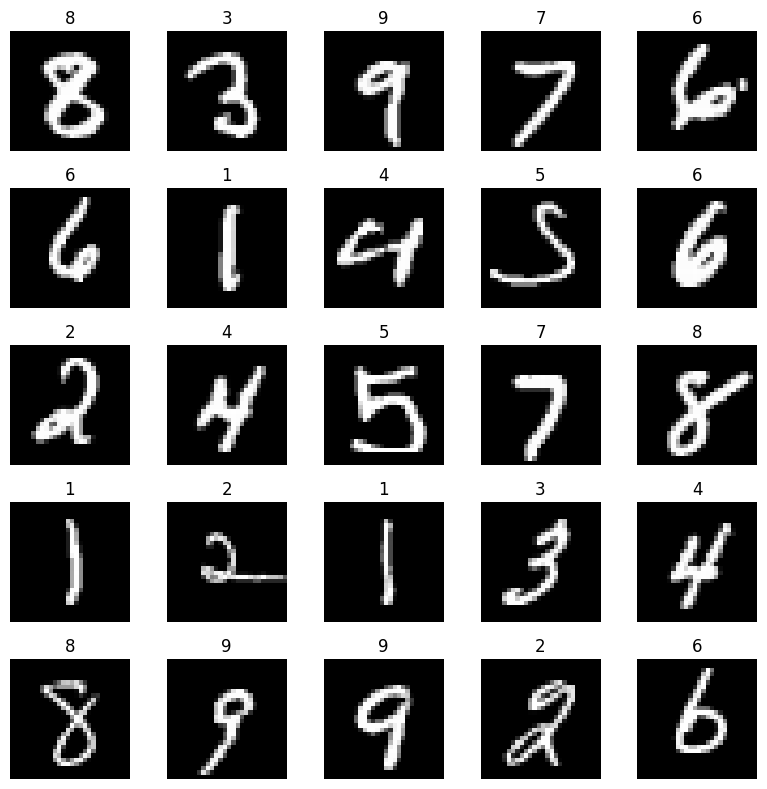

In [8]:
plt.figure(figsize=(8, 8))

for imagenes, etiquetas in datos_entrenamiento.take(1):
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(
            imagenes[i].numpy().squeeze(),
            cmap="gray"
        )
        plt.title(clases[int(etiquetas[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

# Crear el modelo con 2 convoluciones

In [9]:
modelo_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(9, activation="softmax")
])

modelo_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,745 (284.16 KB)

 Trainable params: 72,745 (284.16 KB)

 Non-trainable params: 0 (0.00 B)

Entrenar la red

In [13]:
parada_temprana = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

historial_2 = modelo_2.fit(
    datos_entrenamiento,
    epochs=15,
    validation_data=datos_pruebas,
    callbacks=[parada_temprana]
)

perdida_2, precision_2 = modelo_2.evaluate(datos_pruebas)

print(f"Precisión modelo 2 convoluciones: {precision_2:.4f}")

os.makedirs("modelos", exist_ok=True)
modelo_2.save("modelos/modelo_2_conv.keras")

Epoch 1/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9925 - loss: 0.0251 - val_accuracy: 0.9828 - val_loss: 0.0510
Epoch 2/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9936 - loss: 0.0197 - val_accuracy: 0.9884 - val_loss: 0.0346
Epoch 3/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9950 - loss: 0.0160 - val_accuracy: 0.9891 - val_loss: 0.0347
Epoch 4/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9960 - loss: 0.0125 - val_accuracy: 0.9907 - val_loss: 0.0304
Epoch 5/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9962 - loss: 0.0117 - val_accuracy: 0.9898 - val_loss: 0.0340
Epoch 6/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9966 - loss: 0.0102 - val_accuracy: 0.9867 - val_loss: 0.0522
Epoch 7/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9968 - loss: 0.0089 - val_accuracy: 0.9887 - val_loss: 0.0449
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9907 - loss: 0.0304
Precisión modelo 2 convolucio

In [16]:
import os

os.makedirs("modelos", exist_ok=True)

print("Carpeta 'modelos' creada correctamente.")

Carpeta 'modelos' creada correctamente.


In [15]:
modelo_2.save("modelos/modelo_2_conv.keras")

print("Modelo de 2 convoluciones guardado correctamente.")

Modelo de 2 convoluciones guardado correctamente.


# Crear el modelo con 3 convoluciones

In [11]:
modelo_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(9, activation="softmax")
])

modelo_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_3.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 32)       │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,537 (759.91 KB)

 Trainable params: 194,537 (759.91 KB)

 Non-trainable params: 0 (0.00 B)

Entrenar y guardar el segundo modelo:

In [14]:
historial_3 = modelo_3.fit(
    datos_entrenamiento,
    epochs=15,
    validation_data=datos_pruebas,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

perdida_3, precision_3 = modelo_3.evaluate(datos_pruebas)

print(f"Precisión modelo 3 convoluciones: {precision_3:.4f}")

modelo_3.save("modelos/modelo_3_conv.keras")

Epoch 1/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9909 - loss: 0.0285 - val_accuracy: 0.9886 - val_loss: 0.0348
Epoch 2/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9942 - loss: 0.0182 - val_accuracy: 0.9902 - val_loss: 0.0327
Epoch 3/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9957 - loss: 0.0145 - val_accuracy: 0.9918 - val_loss: 0.0265
Epoch 4/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9957 - loss: 0.0129 - val_accuracy: 0.9930 - val_loss: 0.0222
Epoch 5/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9965 - loss: 0.0101 - val_accuracy: 0.9897 - val_loss: 0.0373
Epoch 6/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9970 - loss: 0.0093 - val_accuracy: 0.9924 - val_loss: 0.0295
Epoch 7/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9971 - loss: 0.0088 - val_accuracy: 0.9900 - val_loss: 0.0359
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9930 - loss: 0.0222
Precisión modelo 3 convolucio

In [17]:
modelo_3.save("modelos/modelo_3_conv.keras")

print("Modelo de 3 convoluciones guardado correctamente.")

Modelo de 3 convoluciones guardado correctamente.


In [18]:
import os

for archivo in [
    "modelos/modelo_2_conv.keras",
    "modelos/modelo_3_conv.keras"
]:
    if os.path.exists(archivo):
        tamaño_mb = os.path.getsize(archivo) / (1024 * 1024)
        print(f"✅ {archivo} — {tamaño_mb:.2f} MB")
    else:
        print(f"❌ No se encontró: {archivo}")

✅ modelos/modelo_2_conv.keras — 0.87 MB
✅ modelos/modelo_3_conv.keras — 2.27 MB


Comparar los resultados

In [ ]:
print("COMPARACIÓN DE MODELOS")
print("----------------------")
print(f"2 convoluciones: {precision_2 * 100:.2f}%")
print(f"3 convoluciones: {precision_3 * 100:.2f}%")

plt.figure(figsize=(10, 5))

plt.plot(
    historial_2.history["val_accuracy"],
    label="2 convoluciones"
)
plt.plot(
    historial_3.history["val_accuracy"],
    label="3 convoluciones"
)

plt.title("Comparación de precisión en validación")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)
plt.show()